In [1]:
import scanpy as sc
import pandas as pd
import pickle
import numpy as np
import matplotlib.pyplot as plt

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# wasserstein metrik 

In [2]:
from scipy.stats import wasserstein_distance

def average_wasserstein_distance(group):
        distances = []
        for i in range(len(group)):
            for j in range(i + 1, len(group)):
                dist = wasserstein_distance(group[i], group[j])
                distances.append(dist)
        return np.mean(distances) if distances else 0

def calculate_wasserstein_comparison(adata, min_lineage_size=2):
    # Filter the adata object based on large_barcodes
    barcode_counts = adata.obs['lineage barcode'].value_counts()
    

    relevant_barcodes = barcode_counts[barcode_counts > min_lineage_size].index

    # Extract the gene expression data
    gene_data = adata.X
    # Create a DataFrame to store the mean cosine similarity for each cell
    results_df = pd.DataFrame(columns=['Wasserstein', 'lineage relationship'])

    
    for lineage in relevant_barcodes:
        # Get the indices of cells in the current lineage
        lineage_indices = adata.obs[adata.obs['lineage barcode'] == lineage].index
        lineage_positions = [adata.obs.index.get_loc(idx) for idx in lineage_indices]
        lineage_data = gene_data[lineage_positions, :]

        # Calculate cosine similarities within the lineage
        wasserstein = average_wasserstein_distance(lineage_data)
        
        # Create a temporary DataFrame for the current lineage
        temp_df = pd.DataFrame({
            'Wasserstein': [wasserstein],
            'lineage relationship': [lineage]
        })
        
        # Append the results to the main DataFrame
        results_df = pd.concat([results_df, temp_df], ignore_index=True)

        # Sample random group of cells with the same size as the lineage
        random_indices = np.random.choice(adata.obs.index, len(lineage_indices), replace=False)
        random_positions = [adata.obs.index.get_loc(idx) for idx in random_indices]
        random_data = gene_data[random_positions, :]
        wasserstein = average_wasserstein_distance(random_data)

        temp_df = pd.DataFrame({
            'Wasserstein': [wasserstein],
            'lineage relationship': ["random"]
        })

        results_df = pd.concat([results_df, temp_df], ignore_index=True)

    results_df["lineage relationship plot"] = ["same lineage" if x != "random" else "different lineage" for x in results_df["lineage relationship"]]
    return results_df

# reading in datasets

In [3]:
# Import necessary libraries
import pickle

# Define the dataset paths
DATASET_PATHS = [
    # treutlein
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/treutlein_all_genes.pkl",

    # weinreb
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/weinreb_all_genes.pkl",

    # junker
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/junker_z5_all_genes.pkl",

    # you1
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage1_barcode_all_genes.pkl",

    # you2
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage2_barcode_all_genes.pkl",

    # you3
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage3_barcode_all_genes.pkl",

    # you4
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage4_barcode_all_genes.pkl",

    # knoblich_day16_1
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_1.pkl",

    # knoblich_day16_2
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_2.pkl",

    # knoblich_day42_1
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_1.pkl",

    # knoblich_day42_2
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_2.pkl",
]


# Define corresponding dataset names
DATASET_NAMES = [
    "He et al.",
    "Weinreb et al.",
    "Spaanjard et al.",
    "You et al. Stage 1",
    "You et al. Stage 2",
    "You et al. Stage 3",
    "You et al. Stage 4",
    "Lindenhofer et al. Day 16 Rep. 1",
    "Lindenhofer et al. Day 16 Rep. 2",
    "Lindenhofer et al. Day 42 Rep. 1",
    "Lindenhofer et al. Day 42 Rep. 2",
]

# Read the datasets and organize them
datasets = []

for path, name in zip(DATASET_PATHS, DATASET_NAMES):
    with open(path, "rb") as f:
        data = pickle.load(f)
    datasets.append((data, name))

for i, (data, name) in enumerate(datasets, start=1):
    print(f"Dataset {i}: {name}, Data type: {type(data)}")

Dataset 1: He et al., Data type: <class 'pandas.core.frame.DataFrame'>
Dataset 2: Weinreb et al., Data type: <class 'pandas.core.frame.DataFrame'>
Dataset 3: Spaanjard et al., Data type: <class 'pandas.core.frame.DataFrame'>
Dataset 4: You et al. Stage 1, Data type: <class 'pandas.core.frame.DataFrame'>
Dataset 5: You et al. Stage 2, Data type: <class 'pandas.core.frame.DataFrame'>
Dataset 6: You et al. Stage 3, Data type: <class 'pandas.core.frame.DataFrame'>
Dataset 7: You et al. Stage 4, Data type: <class 'pandas.core.frame.DataFrame'>
Dataset 8: Lindenhofer et al. Day 16 Rep. 1, Data type: <class 'pandas.core.frame.DataFrame'>
Dataset 9: Lindenhofer et al. Day 16 Rep. 2, Data type: <class 'pandas.core.frame.DataFrame'>
Dataset 10: Lindenhofer et al. Day 42 Rep. 1, Data type: <class 'pandas.core.frame.DataFrame'>
Dataset 11: Lindenhofer et al. Day 42 Rep. 2, Data type: <class 'pandas.core.frame.DataFrame'>


# ncMT genes

In [ ]:
for dataset, name in datasets:
    # Select only autophagy genes from the dataset
    # Ensure `adata_only_MT` creation is valid for your data type
    adata = sc.AnnData(dataset.iloc[:, :-1].values)
    adata.var_names = dataset.columns[:-1]
    adata.obs['lineage barcode'] = dataset.iloc[:, -1].values

    adata.var_names_make_unique()
    
    #nuclear MT genes: 

    mitochondria_related_zebrafish_genes = [
        # Oxidative Phosphorylation (OXPHOS) Support Genes
        "ndufs1", "sdha", "uqcrc1", "cox4i1", "atp5f1a",

        # Mitochondrial Biogenesis Genes
        "ppargc1a", "tfam", "twinkle", "polg",

        # Protein Import Machinery
        "tomm20a", "timm23", "hspa9",

        # Mitochondrial Ribosome Components
        "mrpl12", "mrps22",

        # Reactive Oxygen Species (ROS) Management
        "sod2", "gpx4a", "prdx3",

        # Mitochondrial Dynamics
        "mfn1", "mfn2", "opa1", "dnm1l",

        # Apoptosis Regulation
        "bcl2", "cycs",

        # Cellular Metabolism
        "idh3a", "cpt1a", "glud1a",

        # Mitochondrial Stress Response Genes
        "atf4a", "chop"
    ]

    mitochondria_related_mouse_genes = [
        # Oxidative Phosphorylation (OXPHOS) Support Genes
        "Ndufs1", "Sdha", "Uqcrc1", "Cox4i1", "Atp5f1a",

        # Mitochondrial Biogenesis Genes
        "Ppargc1a", "Tfam", "Twnk", "Polg",

        # Protein Import Machinery
        "Tomm20", "Timm23", "Hspa9",

        # Mitochondrial Ribosome Components
        "Mrpl12", "Mrps22",

        # Reactive Oxygen Species (ROS) Management
        "Sod2", "Gpx4", "Prdx3",

        # Mitochondrial Dynamics
        "Mfn1", "Mfn2", "Opa1", "Dnm1l",

        # Apoptosis Regulation
        "Bcl2", "Cycs",

        # Cellular Metabolism
        "Idh3a", "Cpt1a", "Glud1",

        # Mitochondrial Stress Response Genes
        "Atf4", "Chop"
    ]

    mitochondrial_related_genes = [
        # Oxidative Phosphorylation (OXPHOS) Support Genes
        "NDUFS1", "SDHA", "UQCRC1", "COX4I1", "ATP5F1A",

        # Mitochondrial Biogenesis Genes
        "PPARGC1A", "TFAM", "TWNK", "POLG",

        # Protein Import Machinery
        "TOMM20", "TIMM23", "HSPA9",

        # Mitochondrial Ribosome Components
        "MRPL12", "MRPS22",

        # Reactive Oxygen Species (ROS) Management
        "SOD2", "GPX4", "PRDX3",

        # Mitochondrial Dynamics
        "MFN1", "MFN2", "OPA1", "DNM1L",

        # Apoptosis Regulation
        "BCL2", "CYCS",

        # Cellular Metabolism
        "IDH3A", "CPT1A", "GLUD1",

        # Mitochondrial Stress Response Genes
        "ATF4", "CHOP"
    ]
    
    MT_genes = mitochondria_related_zebrafish_genes + mitochondria_related_mouse_genes + mitochondrial_related_genes

    MT_genes = [gene for gene in MT_genes if gene in dataset.columns]
    adata_only_MT = adata[:, MT_genes]
    
    # Perform Wasserstein distance calculation
    results = calculate_wasserstein_comparison(adata_only_MT, min_lineage_size=6)
    
    # Save results as a pickle file
    sanitized_name = name.replace(" ", "_").replace(".", "").replace(",", "")
    output_path = f"/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/wasserstein_dataframes_for_plotting/df_plotting_wasserstein_distance_ncMT_genes_{sanitized_name}.pkl"
    
    results.to_pickle(output_path)
    print(f"Results saved to {output_path}")
    

Results saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/wasserstein_dataframes_for_plotting/df_plotting_wasserstein_distance_ncMT_genes_He_et_al.pkl
Results saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/wasserstein_dataframes_for_plotting/df_plotting_wasserstein_distance_ncMT_genes_Weinreb_et_al.pkl
Results saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/wasserstein_dataframes_for_plotting/df_plotting_wasserstein_distance_ncMT_genes_Spaanjard_et_al.pkl
Results saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/wasserstein_dataframes_for_plotting/df_plotting_wasserstein_distance_ncMT_genes_You_et_al_Stage_1.pkl
Results saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_R

# autophagy genes 

In [ ]:
for dataset, name in datasets:
    # Select only autophagy genes from the dataset
    # Ensure `adata_only_MT` creation is valid for your data type
    adata = sc.AnnData(dataset.iloc[:, :-1].values)
    adata.var_names = dataset.columns[:-1]
    adata.obs['lineage barcode'] = dataset.iloc[:, -1].values

    adata.var_names_make_unique()
    
    autophagy_genes = [
        "ATG5", "ATG7", "BECN1", "MAP1LC3B", "SQSTM1", "GABARAPL1", 
        "ULK1", "WIPI2", "ATG12", "ATG16L1", "VPS34", "UVRAG", 
        "PINK1", "PRKN", "BNIP3", "DRAM1", "GABARAP", "LC3B", 
        "ATG4B", "RUBCN", "FIP200", "AMBRA1"
    ]

    zebrafish_autophagy_genes = [
        "atg5", "atg7", "becn1", "map1lc3b", "sqstm1", "gabarapl1", 
        "ulk1", "wipi2", "atg12", "atg16l1", "pik3c3", "uvrag", 
        "pink1", "parkin", "bnip3", "dram1", "gabarap", "map1lc3b", 
        "atg4b", "rubcn", "rb1cc1", "ambra1"
    ]

    mouse_autophagy_genes = [
        "Atg5", "Atg7", "Becn1", "Map1lc3b", "Sqstm1", "Gabarapl1", 
        "Ulk1", "Wipi2", "Atg12", "Atg16l1", "Pik3c3", "Uvrag", 
        "Pink1", "Prkn", "Bnip3", "Dram1", "Gabarap", "Map1lc3b", 
        "Atg4b", "Rubcn", "Rb1cc1", "Ambra1"
    ]

    autophagy_genes = autophagy_genes + zebrafish_autophagy_genes + mouse_autophagy_genes
    autophagy_genes = [gene for gene in autophagy_genes if gene in dataset.columns]
    
    adata_only_MT = adata[:, autophagy_genes]
    
    # Perform Wasserstein distance calculation
    results = calculate_wasserstein_comparison(adata_only_MT, min_lineage_size=6)
    
    # Save results as a pickle file
    sanitized_name = name.replace(" ", "_").replace(".", "").replace(",", "")
    output_path = f"/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/wasserstein_dataframes_for_plotting/df_plotting_wasserstein_distance_AT_genes_{sanitized_name}.pkl"
    
    results.to_pickle(output_path)
    print(f"Results saved to {output_path}")
    

In [ ]:
import os
import pickle
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

# Define the directory paths
input_dir = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/wasserstein_dataframes_for_plotting/"
output_dir = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/"

# Ensure output directory exists
os.makedirs(output_dir, exist_ok=True)

# List of pickle files
pickle_files = [
    "df_plotting_wasserstein_distance_AT_genes_He_et_al.pkl",
    "df_plotting_wasserstein_distance_AT_genes_Weinreb_et_al.pkl",
    "df_plotting_wasserstein_distance_AT_genes_Spaanjard_et_al.pkl",
    "df_plotting_wasserstein_distance_AT_genes_You_et_al_Stage_1.pkl",
    "df_plotting_wasserstein_distance_AT_genes_You_et_al_Stage_2.pkl",
    "df_plotting_wasserstein_distance_AT_genes_You_et_al_Stage_3.pkl",
    "df_plotting_wasserstein_distance_AT_genes_You_et_al_Stage_4.pkl",
    "df_plotting_wasserstein_distance_AT_genes_Lindenhofer_et_al_Day_16_Rep_1.pkl",
    "df_plotting_wasserstein_distance_AT_genes_Lindenhofer_et_al_Day_16_Rep_2.pkl",
    "df_plotting_wasserstein_distance_AT_genes_Lindenhofer_et_al_Day_42_Rep_1.pkl",
    "df_plotting_wasserstein_distance_AT_genes_Lindenhofer_et_al_Day_42_Rep_2.pkl",
]

# Process each pickle file
for pkl_file in pickle_files:
    input_path = os.path.join(input_dir, pkl_file)
    
    # Load the results DataFrame
    with open(input_path, "rb") as f:
        df = pickle.load(f)
    
    # Define plot parameters
    x = 'lineage relationship plot'
    y = 'Wasserstein'
    pairs = [
        ("same lineage", "different lineage")  # Replace with actual categories in your data
    ]
    
    # Create the seaborn plot
    plt.figure(figsize=(3, 6))
    ax = sns.boxplot(x=x, y=y, data=df, showfliers=False)
    sns.stripplot(x=x, y=y, data=df, color='black', size=2, alpha=0.2, dodge=True, jitter=0.25, )
    
    # Add statistical annotations
    annotator = Annotator(ax, pairs, data=df, x=x, y=y)
    annotator.configure(test='t-test_ind', text_format='star', loc='inside')  # Adjust test type as needed
    annotator.apply_and_annotate()
    
    # Customize the plot
    ax.set_ylabel('Wasserstein Distance')
    ax.set_xlabel('')
    ax.set_title('')
    
    # Save the plot
    plot_name = pkl_file.replace("df_plotting_wasserstein_distance_", "").replace(".pkl", "_wasserstein_box.pdf")
    output_path = os.path.join(output_dir, plot_name)
    plt.savefig(output_path, bbox_inches='tight')
    print(f"Plot saved to {output_path}")
    
    plt.close()


# MT Genes

In [ ]:
for dataset, name in datasets:
    # Select only autophagy genes from the dataset
    # Ensure `adata_only_MT` creation is valid for your data type
    adata = sc.AnnData(dataset.iloc[:, :-1].values)
    adata.var_names = dataset.columns[:-1]
    adata.obs['lineage barcode'] = dataset.iloc[:, -1].values

    adata.var_names_make_unique()
    
    MT_genes = [
    "MT-ND1", "MT-ND2", "MT-CO1", "MT-CO2", "MT-ATP8", "MT-ATP6", "MT-CO3", "MT-ND3", 
    "MT-ND4L", "MT-ND4", "MT-ND5", "MT-ND6", "MT-CYB", "mt-Nd1", "mt-Nd2", "mt-Co1", 
    "mt-Co2", "mt-Atp8", "mt-Atp6", "mt-Co3", "mt-Nd3", "mt-Nd4l", "mt-Nd4", "mt-Nd5", 
    "mt-Nd6", "mt-Cytb", "NC_002333.17", "NC_002333.12", "mt-nd3", "NC_002333.3", 
    "mt-nd4l", "mt-nd4", "NC_002333.16", "NC_002333.15", "mt-nd5", "mt-nd6", "mt-cyb", 
    "NC_002333.22", "NC_002333.10", "NC_002333.4", "NC_002333.19", "mt-nd1", 
    "NC_002333.6", "NC_002333.14", "mt-nd2", "NC_002333.7", "NC_002333.5", 
    "NC_002333.13", "NC_002333.18", "NC_002333.1", "mt-co1", "NC_002333.24"
    ]

    MT_genes = [gene for gene in MT_genes if gene in dataset.columns]
    adata_only_MT = adata[:, MT_genes]
    
    # Perform Wasserstein distance calculation
    results = calculate_wasserstein_comparison(adata_only_MT, min_lineage_size=6)
    
    # Save results as a pickle file
    sanitized_name = name.replace(" ", "_").replace(".", "").replace(",", "")
    output_path = f"/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/wasserstein_dataframes_for_plotting/df_plotting_wasserstein_distance_MT_genes_{sanitized_name}.pkl"
    
    results.to_pickle(output_path)
    print(f"Results saved to {output_path}")
    

# plotting 

In [ ]:
import os
import pickle
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

# Define the directory paths
input_dir = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/wasserstein_dataframes_for_plotting/"
pickle_files = [
    "df_plotting_wasserstein_distance_MT_genes_He_et_al.pkl",
    "df_plotting_wasserstein_distance_MT_genes_Weinreb_et_al.pkl",
    "df_plotting_wasserstein_distance_MT_genes_Spaanjard_et_al.pkl",
    "df_plotting_wasserstein_distance_MT_genes_You_et_al_Stage_1.pkl",
    "df_plotting_wasserstein_distance_MT_genes_You_et_al_Stage_2.pkl",
    "df_plotting_wasserstein_distance_MT_genes_You_et_al_Stage_3.pkl",
    "df_plotting_wasserstein_distance_MT_genes_You_et_al_Stage_4.pkl",
    "df_plotting_wasserstein_distance_MT_genes_Lindenhofer_et_al_Day_16_Rep_1.pkl",
    "df_plotting_wasserstein_distance_MT_genes_Lindenhofer_et_al_Day_16_Rep_2.pkl",
    "df_plotting_wasserstein_distance_MT_genes_Lindenhofer_et_al_Day_42_Rep_1.pkl",
    "df_plotting_wasserstein_distance_MT_genes_Lindenhofer_et_al_Day_42_Rep_2.pkl",
]

# Number of rows and columns for the subplot grid
n_cols = 4
n_rows = -(-len(pickle_files) // n_cols)  # Ceiling division

# Create a figure for subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows), constrained_layout=True)
axes = axes.flatten()  # Flatten axes for easy iteration

# Plot each dataset
for i, pkl_file in enumerate(pickle_files):
    input_path = os.path.join(input_dir, pkl_file)
    
    # Load the results DataFrame
    with open(input_path, "rb") as f:
        df = pickle.load(f)
    
    # Define plot parameters
    x = 'lineage relationship plot'
    y = 'Wasserstein'
    pairs = [
        ("same lineage", "different lineage")  # Replace with actual categories in your data
    ]
    
    # Select the current axis
    ax = axes[i]
    
    # Create the seaborn plot
    sns.boxplot(x=x, y=y, data=df, showfliers=False, ax=ax)
    sns.stripplot(x=x, y=y, data=df, color='black', size=2, alpha=0.2, dodge=True, jitter=0.25, ax=ax)
    
    # Add statistical annotations
    annotator = Annotator(ax, pairs, data=df, x=x, y=y)
    annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')  # Adjust test type as needed
    annotator.apply_and_annotate()
    
    # Customize the plot
    ax.set_title(pkl_file.replace("df_plotting_wasserstein_distance_", "").replace(".pkl", "").replace("_", " "))
    ax.set_ylabel('Wasserstein Distance')
    ax.set_xlabel('')
    
# Hide unused axes if the number of plots is less than the grid size
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Show all plots in a grid
plt.show()


# plotting all together

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

MT_same lineage vs. MT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:2.734e-54 U_stat=1.537e+04
AT_same lineage vs. AT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.750e-11 U_stat=3.621e+04
ncMT_same lineage vs. ncMT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:5.534e-15 U_stat=3.363e+04
Plot saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/combined_plot_AT genes He et al_no_legend.pdf


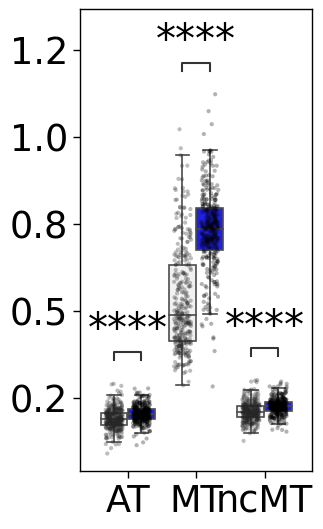

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

MT_same lineage vs. MT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:2.442e-69 U_stat=1.485e+06
AT_same lineage vs. AT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:2.399e-67 U_stat=1.495e+06
ncMT_same lineage vs. ncMT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.144e-119 U_stat=1.265e+06
Plot saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/combined_plot_AT genes Weinreb et al_no_legend.pdf


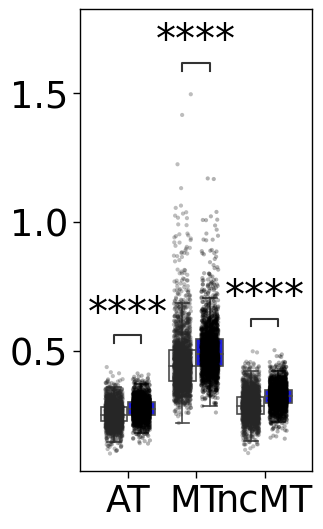

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

MT_same lineage vs. MT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:2.412e-01 U_stat=5.808e+03
AT_same lineage vs. AT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:8.593e-02 U_stat=5.540e+03
ncMT_same lineage vs. ncMT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.908e-01 U_stat=5.741e+03
Plot saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/combined_plot_AT genes Spaanjard et al_no_legend.pdf


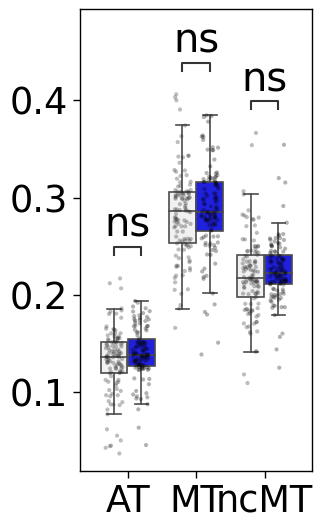

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/statannotations/_Plotter.py:337: UserWarning: Invalid x-position found. Are the same parameters passed to seaborn and statannotations calls? or are there few data points?
  warnings.warn(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

MT_same lineage vs. MT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.000e-01 U_stat=0.000e+00
AT_same lineage vs. AT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.000e-01 U_stat=0.000e+00
ncMT_same lineage vs. ncMT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:4.000e-01 U_stat=2.000e+00
Plot saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/combined_plot_AT genes You et al Stage 1_no_legend.pdf


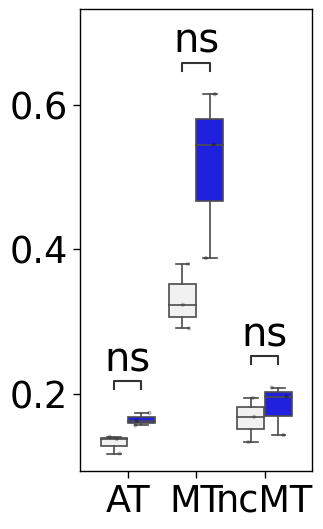

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

MT_same lineage vs. MT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.284e-29 U_stat=3.124e+04
AT_same lineage vs. AT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.883e-12 U_stat=4.268e+04
ncMT_same lineage vs. ncMT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.900e-04 U_stat=5.157e+04
Plot saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/combined_plot_AT genes You et al Stage 2_no_legend.pdf


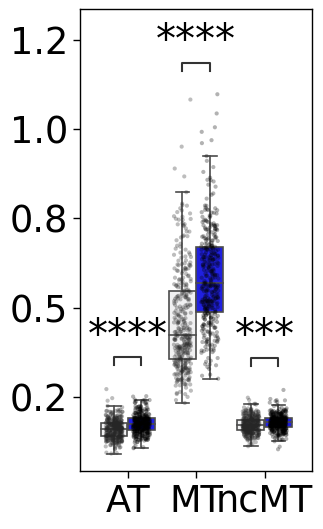

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

MT_same lineage vs. MT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:4.099e-32 U_stat=2.438e+04
AT_same lineage vs. AT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.597e-10 U_stat=3.725e+04
ncMT_same lineage vs. ncMT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:7.122e-06 U_stat=4.179e+04
Plot saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/combined_plot_AT genes You et al Stage 3_no_legend.pdf


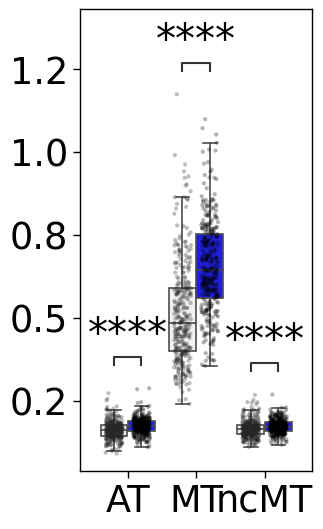

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

MT_same lineage vs. MT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:3.817e-03 U_stat=1.050e+02


/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/statannotations/_Plotter.py:337: UserWarning: Invalid x-position found. Are the same parameters passed to seaborn and statannotations calls? or are there few data points?
  warnings.warn(


AT_same lineage vs. AT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:7.409e-02 U_stat=1.490e+02
ncMT_same lineage vs. ncMT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:2.472e-01 U_stat=1.740e+02
Plot saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/combined_plot_AT genes You et al Stage 4_no_legend.pdf


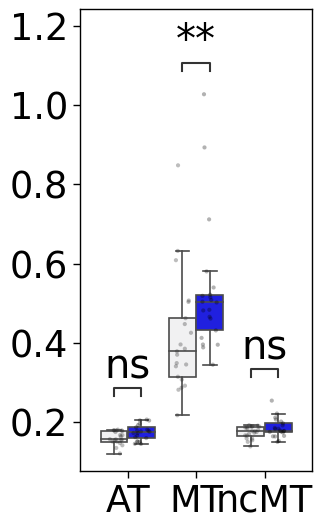

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

MT_same lineage vs. MT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:6.209e-01 U_stat=1.377e+03
AT_same lineage vs. AT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:3.005e-01 U_stat=1.289e+03
ncMT_same lineage vs. ncMT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:2.203e-01 U_stat=1.258e+03
Plot saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/combined_plot_AT genes Lindenhofer et al Day 16 Rep 1_no_legend.pdf


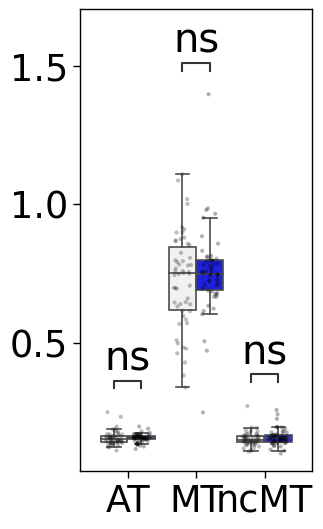

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

MT_same lineage vs. MT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:7.200e-01 U_stat=1.931e+03
AT_same lineage vs. AT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.349e-01 U_stat=1.568e+03
ncMT_same lineage vs. ncMT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.637e-01 U_stat=1.588e+03
Plot saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/combined_plot_AT genes Lindenhofer et al Day 16 Rep 2_no_legend.pdf


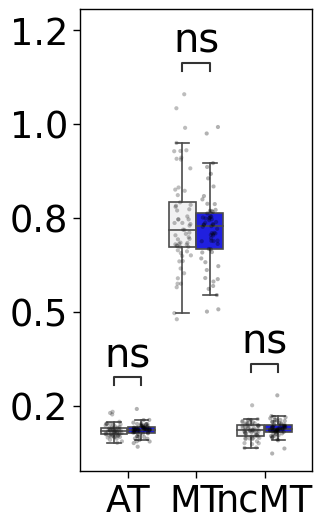

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

MT_same lineage vs. MT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:5.947e-03 U_stat=5.240e+02
AT_same lineage vs. AT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:3.074e-01 U_stat=4.240e+02
ncMT_same lineage vs. ncMT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.212e-02 U_stat=5.100e+02
Plot saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/combined_plot_AT genes Lindenhofer et al Day 42 Rep 1_no_legend.pdf


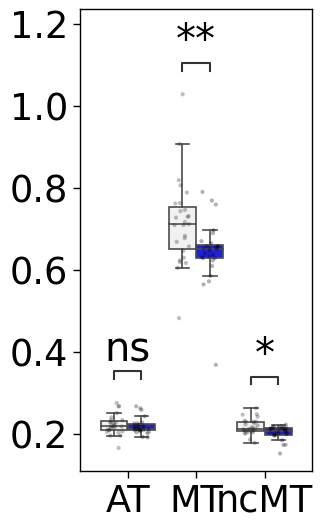

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

MT_same lineage vs. MT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.010e-01 U_stat=2.113e+03
AT_same lineage vs. AT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:4.577e-01 U_stat=1.658e+03
ncMT_same lineage vs. ncMT_different lineage: Mann-Whitney-Wilcoxon test two-sided, P_val:1.816e-01 U_stat=1.545e+03
Plot saved to /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/combined_plot_AT genes Lindenhofer et al Day 42 Rep 2_no_legend.pdf


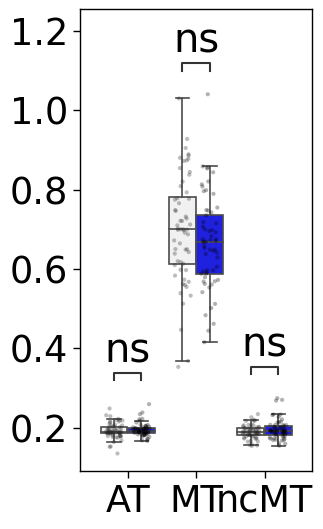

In [1]:
import os
import pickle
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
from matplotlib.ticker import FormatStrFormatter

# Define the directory path
input_dir = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/wasserstein_dataframes_for_plotting/"

# Base filenames for datasets
base_files = [
    "df_plotting_wasserstein_distance_AT_genes_He_et_al.pkl",
    "df_plotting_wasserstein_distance_AT_genes_Weinreb_et_al.pkl",
    "df_plotting_wasserstein_distance_AT_genes_Spaanjard_et_al.pkl",
    "df_plotting_wasserstein_distance_AT_genes_You_et_al_Stage_1.pkl",
    "df_plotting_wasserstein_distance_AT_genes_You_et_al_Stage_2.pkl",
    "df_plotting_wasserstein_distance_AT_genes_You_et_al_Stage_3.pkl",
    "df_plotting_wasserstein_distance_AT_genes_You_et_al_Stage_4.pkl",
    "df_plotting_wasserstein_distance_AT_genes_Lindenhofer_et_al_Day_16_Rep_1.pkl",
    "df_plotting_wasserstein_distance_AT_genes_Lindenhofer_et_al_Day_16_Rep_2.pkl",
    "df_plotting_wasserstein_distance_AT_genes_Lindenhofer_et_al_Day_42_Rep_1.pkl",
    "df_plotting_wasserstein_distance_AT_genes_Lindenhofer_et_al_Day_42_Rep_2.pkl",
]




# Loop over datasets to create combined plots
for base_file in base_files:
    # Generate corresponding filenames for AT, MT, and ncMT
    file_AT = os.path.join(input_dir, base_file)
    file_MT = os.path.join(input_dir, base_file.replace("AT", "MT"))
    file_ncMT = os.path.join(input_dir, base_file.replace("AT", "ncMT"))
    
    # Load DataFrames if they exist
    data_frames = {}
    for gene_type, file_path in [("AT", file_AT), ("MT", file_MT), ("ncMT", file_ncMT)]:
        with open(file_path, "rb") as f:
            data_frames[gene_type] = pickle.load(f)



    # Combine the DataFrames, adding a 'Gene Set' and 'Lineage Relationship' column
    combined_df = []
    for gene_type, df in data_frames.items():
        df["Gene Set"] = gene_type
        combined_df.append(df)
    combined_df = pd.concat(combined_df, ignore_index=True)
    
    # Define plot parameters
    x = 'Gene Set'
    y = 'Wasserstein'
    hue = 'lineage relationship plot'  # Ensure column matches your data
    
    # Define statistical comparison pairs
    pairs = [
        [("AT", "same lineage"), ("AT", "different lineage")],
        [("MT", "same lineage"), ("MT", "different lineage")],
        [("ncMT", "same lineage"), ("ncMT", "different lineage")],
    ]
    
    # Create the combined plot
    plt.figure(figsize=(3, 6))

    #make text size bigger 
    sns.set_context("paper", font_scale=3)

    
    # Create boxplot
    ax = sns.boxplot(
        x=x, y=y, hue=hue, data=combined_df, showfliers=False, color="blue"
    )
    
    # Add stripplot
    sns.stripplot(
        x=x, y=y, hue=hue, data=combined_df, dodge=True, size=3,
        alpha=0.3, jitter=0.25, color="black"
    )

    # Add statistical annotations
    annotator = Annotator(ax, pairs, data=combined_df, x=x, y=y, hue=hue)
    annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')  # Adjust test as needed
    annotator.apply_and_annotate()
    
    # Customize the plot
    plot_title = base_file.replace("df_plotting_wasserstein_distance_", "").replace(".pkl", "").replace("_", " ")
    #ax.set_title(f"Combined Plot for {plot_title}")
    ax.set_title("")
    ax.set_ylabel('')
    ax.set_xlabel('')
    
    # on y label only write on decimal number on y ticks
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

    # Adjust legend to display correctly
    #handles, labels = ax.get_legend_handles_labels()
    #plt.legend(handles[:4], labels[:4], title="Lineage Relationship", bbox_to_anchor=(1, 1), loc="upper left")
    
    #no legend
    ax.get_legend().remove()

    # Save the plot
    output_dir = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/"
    os.makedirs(output_dir, exist_ok=True)
    output_path = os.path.join(output_dir, f"combined_plot_{plot_title}_no_legend.pdf")
    plt.savefig(output_path, bbox_inches='tight')
    print(f"Plot saved to {output_path}")
    
    plt.show()
    plt.close()
